Q2

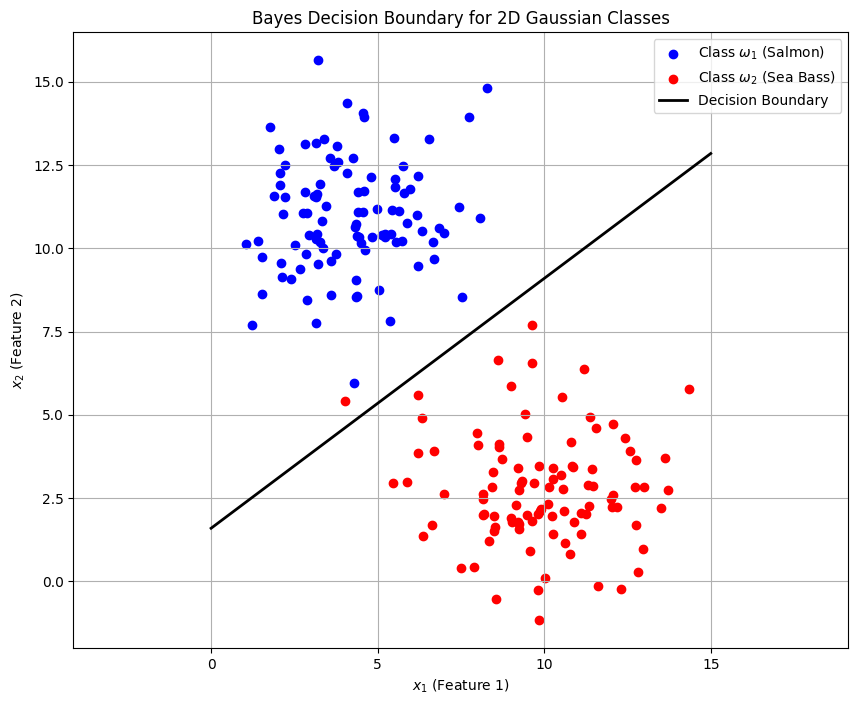

In [2]:
import numpy as np
import matplotlib.pyplot as plt
mu1 = np.array([4, 11])
mu2 = np.array([10, 3])
cov = np.array([[3, 0], [0, 3]])
p1 = 0.6
p2 = 0.4
n_samples = 100
samples1 = np.random.multivariate_normal(mu1, cov, n_samples)
samples2 = np.random.multivariate_normal(mu2, cov, n_samples)
plt.figure(figsize=(10, 8))
plt.scatter(samples1[:, 0], samples1[:, 1], c='blue', label='Class $\omega_1$ (Salmon)')
plt.scatter(samples2[:, 0], samples2[:, 1], c='red', label='Class $\omega_2$ (Sea Bass)')
x_boundary = np.linspace(0, 15, 100)
ln_term = (3/8) * np.log(p2 / p1)
constant_term = (14/8) + ln_term 
y_boundary = 0.75 * x_boundary + 1.75 + (3/8) * np.log(p2 / p1)
plt.plot(x_boundary, y_boundary, 'k-', linewidth=2, label='Decision Boundary')
plt.title('Bayes Decision Boundary for 2D Gaussian Classes')
plt.xlabel('$x_1$ (Feature 1)')
plt.ylabel('$x_2$ (Feature 2)')
plt.legend()
plt.grid(True)
plt.axis('equal')
plt.show()

Q7

part 1

$$
\begin{align*}
P(T=1 | D=1) &= 0.99 \\
P(T=0 | D=0) &= 0.99 \\
P(D=1) &= 0.001 \\
\hline \\
P(D=0) &= 1 - P(D=1) = 1 - 0.001 = 0.999 \\
P(T=1 | D=0) &= 1 - P(T=0 | D=0) = 1 - 0.99 = 0.01 \\
\\
P(T=1) &= P(T=1|D=1)P(D=1) + P(T=1|D=0)P(D=0) \\
P(T=1) &= (0.99 \cdot 0.001) + (0.01 \cdot 0.999) \\
P(T=1) &= 0.00099 + 0.00999 = 0.01098 \\
\\
P(D=1 | T=1) &= \frac{P(T=1 | D=1) \cdot P(D=1)}{P(T=1)} \\
P(D=1 | T=1) &= \frac{0.99 \cdot 0.001}{0.01098} = \frac{0.00099}{0.01098} \\
P(D=1 | T=1) &\approx 0.09016
\end{align*}
$$

Q7

part 2

In [5]:
import numpy as np
X = np.array([[0, 1],[1, 1],[0, 1],[1, 1],[1, 1],[0, 0],[1, 0],[1, 0],[1, 1],[1, 0]])
y = np.array([1, 1, 0, 1, 1, 0, 1, 0, 1, 0])
N = len(y)
N1 = np.sum(y == 1)
N0 = N - N1
p_y1 = N1 / N
p_y0 = N0 / N
print(f"P(y=1) = {N1}/{N} = {p_y1}")
print(f"P(y=0) = {N0}/{N} = {p_y0}")
print()
X1 = X[y == 1]
X0 = X[y == 0]
p_x_given_y1 = np.mean(X1, axis=0)
p_x1_y1 = p_x_given_y1[0]
p_x2_y1 = p_x_given_y1[1]
p_x_given_y0 = np.mean(X0, axis=0)
p_x1_y0 = p_x_given_y0[0]
p_x2_y0 = p_x_given_y0[1]
print(f"P(x1=1 | y=1) = {np.sum(X1[:, 0])}/{N1} = {p_x1_y1:.4f}")
print(f"P(x2=1 | y=1) = {np.sum(X1[:, 1])}/{N1} = {p_x2_y1:.4f}")
print(f"P(x1=1 | y=0) = {np.sum(X0[:, 0])}/{N0} = {p_x1_y0:.4f}")
print(f"P(x2=1 | y=0) = {np.sum(X0[:, 1])}/{N0} = {p_x2_y0:.4f}")
print()
x_test = np.array([1, 1])
prob_x_given_y1 = p_x1_y1 * p_x2_y1
prob_x_given_y0 = p_x1_y0 * p_x2_y0
score_y1 = prob_x_given_y1 * p_y1
score_y0 = prob_x_given_y0 * p_y0
print(f"Score(y=1) ∝ P(x|y=1)P(y=1) = ({p_x1_y1:.2f} * {p_x2_y1:.2f}) * {p_y1} = {score_y1:.4f}")
print(f"Score(y=0) ∝ P(x|y=0)P(y=0) = ({p_x1_y0:.2f} * {p_x2_y0:.2f}) * {p_y0} = {score_y0:.4f}")
print()
if score_y1 > score_y0:
    print("Result: Score(y=1) > Score(y=0), therefore label y=1 is chosen.")
else:
    print("Result: Score(y=0) > Score(y=1), therefore label y=0 is chosen.")

P(y=1) = 6/10 = 0.6
P(y=0) = 4/10 = 0.4

P(x1=1 | y=1) = 5/6 = 0.8333
P(x2=1 | y=1) = 5/6 = 0.8333
P(x1=1 | y=0) = 2/4 = 0.5000
P(x2=1 | y=0) = 1/4 = 0.2500

Score(y=1) ∝ P(x|y=1)P(y=1) = (0.83 * 0.83) * 0.6 = 0.4167
Score(y=0) ∝ P(x|y=0)P(y=0) = (0.50 * 0.25) * 0.4 = 0.0500

Result: Score(y=1) > Score(y=0), therefore label y=1 is chosen.


### (a) Compute the estimates of the class prior probabilities
قراره با شمارش احتمالات پیشین رو حساب کنیم:
تعداد کل نمونه‌ها $N = 10$.
* تعداد نمونه‌های $y=1$ (کلاس ۱): $N_1 = 6$
* تعداد نمونه‌های $y=0$ (کلاس ۰): $N_0 = 4$

بنابراین، احتمالات پیشین عبارتند از:
$$P(y=1) = \frac{N_1}{N} = \frac{6}{10} = 0.6$$
$$P(y=0) = \frac{N_0}{N} = \frac{4}{10} = 0.4$$

### (b) Compute the estimates of the 4 conditional probabilities
ما احتمالات شرطی را با شمارش ویژگی‌ها در هر کلاس به دست می‌آوریم.

**برای کلاس $y=1$ (که $N_1=6$ نمونه دارد):**
* $P(x_1=1 | y=1) = \frac{\text{Count}(x_1=1 \text{ and } y=1)}{N_1} = \frac{5}{6} \approx 0.833$
* $P(x_2=1 | y=1) = \frac{\text{Count}(x_2=1 \text{ and } y=1)}{N_1} = \frac{5}{6} \approx 0.833$

**برای کلاس $y=0$ (که $N_0=4$ نمونه دارد):**
* $P(x_1=1 | y=0) = \frac{\text{Count}(x_1=1 \text{ and } y=0)}{N_0} = \frac{2}{4} = 0.5$
* $P(x_2=1 | y=0) = \frac{\text{Count}(x_2=1 \text{ and } y=0)}{N_0} = \frac{1}{4} = 0.25$

### (c) What is the most likely label for the test example? (Show your work)
$$\text{Score}(y=1) \propto P(x_1=1 | y=1) \cdot P(x_2=1 | y=1) \cdot P(y=1)$$
$$\text{Score}(y=1) \propto \left(\frac{5}{6}\right) \cdot \left(\frac{5}{6}\right) \cdot (0.6)$$
$$\text{Score}(y=1) \propto \frac{25}{36} \cdot \frac{6}{10} = \frac{150}{360} = \frac{5}{12} \approx 0.4167$$
$$\text{Score}(y=0) \propto P(x_1=1 | y=0) \cdot P(x_2=1 | y=0) \cdot P(y=0)$$
$$\text{Score}(y=0) \propto \left(\frac{1}{2}\right) \cdot \left(\frac{1}{4}\right) \cdot (0.4)$$
$$\text{Score}(y=0) \propto \frac{1}{8} \cdot \frac{4}{10} = \frac{4}{80} = \frac{1}{20} = 0.05$$
$$0.4167 \quad (\text{برای } y=1) \quad > \quad 0.05 \quad (\text{برای } y=0)$$
چون $y = 1$ بیشتر هست پس لیبل نمونه تستی مون میشه یک.

Q8

In [10]:
import numpy as np
TRAIN_FILE = 'train_8'
TEST_FILE = 'test_8'
spam_word_counts = {}
ham_word_counts = {}
total_spam_words = 0
total_ham_words = 0
total_spam_emails = 0
total_ham_emails = 0
vocabulary = set()
with open(TRAIN_FILE, 'r') as f:
    for line in f:
        parts = line.split()
        if len(parts) < 2:
            continue
        label = parts[1]
        if label == 'spam':
            total_spam_emails += 1
        elif label == 'ham':
            total_ham_emails += 1
        else:
            continue
        word_info = parts[2:]
        for i in range(0, len(word_info), 2):
            if i + 1 < len(word_info):
                try:
                    word_id = word_info[i]
                    count = int(word_info[i+1])
                    vocabulary.add(word_id)
                    if label == 'spam':
                        spam_word_counts[word_id] = spam_word_counts.get(word_id, 0) + count
                        total_spam_words += count
                    else:
                        ham_word_counts[word_id] = ham_word_counts.get(word_id, 0) + count
                        total_ham_words += count
                except ValueError:
                    pass
total_emails = total_spam_emails + total_ham_emails
p_spam = total_spam_emails / total_emails
p_ham = total_ham_emails / total_emails
print(f"Q8.2: Prior Probabilities:")
print(f"Total training emails processed: {total_emails}")
print(f"P(spam) = {total_spam_emails}/{total_emails} = {p_spam:.4f}")
print(f"P(ham) = {total_ham_emails}/{total_emails} = {p_ham:.4f}")
print()
vocab_size = len(vocabulary)
def calculate_spam_likelihood(word_id):
    count = spam_word_counts.get(word_id, 0)
    numerator = count + 1
    denominator = total_spam_words + vocab_size
    return numerator / denominator

def calculate_ham_likelihood(word_id):
    count = ham_word_counts.get(word_id, 0)
    numerator = count + 1
    denominator = total_ham_words + vocab_size
    return numerator / denominator

print(f"Q8.3: Model Parameters")
print(f"Vocabulary Size (m): {vocab_size}")
print(f"Total words in spam docs: {total_spam_words}")
print(f"Total words in ham docs: {total_ham_words}")
print()
spam_likelihoods = {}
ham_likelihoods = {}
for word_id in vocabulary:
    spam_likelihoods[word_id] = calculate_spam_likelihood(word_id)
    ham_likelihoods[word_id] = calculate_ham_likelihood(word_id)

sorted_spam_words = sorted(spam_likelihoods.items(), key=lambda item: item[1], reverse=True)
sorted_ham_words = sorted(ham_likelihoods.items(), key=lambda item: item[1], reverse=True)

print(f"Top 5 Most Likely Words")
print("Top 5 Spam words (word_id: probability):")
for i in range(5):
    word_id, prob = sorted_spam_words[i]
    print(f"  Word '{word_id}': {prob:.6f}")

print("\nTop 5 Ham words (word_id: probability):")
for i in range(5):
    word_id, prob = sorted_ham_words[i]
    print(f"  Word '{word_id}': {prob:.6f}")

Q8.2: Prior Probabilities:
Total training emails processed: 9000
P(spam) = 5163/9000 = 0.5737
P(ham) = 3837/9000 = 0.4263

Q8.3: Model Parameters
Vocabulary Size (m): 1000
Total words in spam docs: 1655369
Total words in ham docs: 1577820

Top 5 Most Likely Words
Top 5 Spam words (word_id: probability):
  Word 'enron': 0.038194
  Word 'a': 0.023619
  Word 'corp': 0.021738
  Word 'the': 0.021425
  Word 'to': 0.019687

Top 5 Ham words (word_id: probability):
  Word 'aaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaa': 0.044322
  Word 'enron': 0.042444
  Word 'the': 0.033169
  Word 'to': 0.025330
  Word 'a': 0.017737


In [13]:
import numpy as np
import math
from sklearn.metrics import confusion_matrix, classification_report
print(f"\nQ8.4: Testing Phase & Detailed Analysis")
log_p_spam = math.log(p_spam)
log_p_ham = math.log(p_ham)
log_likelihoods_spam = {}
log_likelihoods_ham = {}
denom_spam = total_spam_words + vocab_size
denom_ham = total_ham_words + vocab_size
log_prob_unknown_spam = math.log(1.0 / denom_spam)
log_prob_unknown_ham = math.log(1.0 / denom_ham)
for word_id in vocabulary:
    count_spam = spam_word_counts.get(word_id, 0)
    count_ham = ham_word_counts.get(word_id, 0)
    log_likelihoods_spam[word_id] = math.log((count_spam + 1) / denom_spam)
    log_likelihoods_ham[word_id] = math.log((count_ham + 1) / denom_ham)
total_test_emails = 0
correct_predictions = 0
all_predictions = []
all_actuals = []
with open(TEST_FILE, 'r') as f:
    for line in f:
        parts = line.split()
        if len(parts) < 2:
            continue            
        actual_label = parts[1]
        if actual_label not in ('spam', 'ham'):
            continue
        total_test_emails += 1
        log_score_spam = log_p_spam
        log_score_ham = log_p_ham
        word_info = parts[2:]
        for i in range(0, len(word_info), 2):
            if i + 1 < len(word_info):
                try:
                    word_id = word_info[i]
                    count = int(word_info[i+1])
                    if word_id in vocabulary:
                        log_score_spam += count * log_likelihoods_spam[word_id]
                        log_score_ham += count * log_likelihoods_ham[word_id]
                    else:
                        log_score_spam += count * log_prob_unknown_spam
                        log_score_ham += count * log_prob_unknown_ham
                except ValueError:
                    pass
        prediction = 'ham'
        if log_score_spam > log_score_ham:
            prediction = 'spam'
        all_predictions.append(prediction)
        all_actuals.append(actual_label)
        if prediction == actual_label:
            correct_predictions += 1
accuracy = (correct_predictions / total_test_emails) * 100
print(f"Testing complete.")
print(f"Total test emails: {total_test_emails}")
print(f"Correct predictions: {correct_predictions}")
print(f"Accuracy: {accuracy:.2f}%")
print("-" * 30)
print("Detailed Performance Analysis")
labels = ['spam', 'ham']
print("Confusion Matrix:")
cm = confusion_matrix(all_actuals, all_predictions, labels=labels)
print(f"        (Pred Spam) (Pred Ham)")
print(f"(Actual Spam) {cm[0,0]:<10} {cm[0,1]:<10}")
print(f"(Actual Ham)  {cm[1,0]:<10} {cm[1,1]:<10}")
print("-" * 30)
print("Classification Report:")
report = classification_report(all_actuals, all_predictions, labels=labels)
print(report)


Q8.4: Testing Phase & Detailed Analysis
Testing complete.
Total test emails: 1000
Correct predictions: 902
Accuracy: 90.20%
------------------------------
Detailed Performance Analysis
Confusion Matrix:
        (Pred Spam) (Pred Ham)
(Actual Spam) 560        20        
(Actual Ham)  78         342       
------------------------------
Classification Report:
              precision    recall  f1-score   support

        spam       0.88      0.97      0.92       580
         ham       0.94      0.81      0.87       420

    accuracy                           0.90      1000
   macro avg       0.91      0.89      0.90      1000
weighted avg       0.91      0.90      0.90      1000




Q8.5: Varying the 'm' parameter
Testing with k = 1...
k = 1, Accuracy = 90.20%
Testing with k = 10...
k = 10, Accuracy = 90.40%
Testing with k = 100...
k = 100, Accuracy = 90.40%
Testing with k = 1000...
k = 1000, Accuracy = 87.10%
Testing with k = 10000...
k = 10000, Accuracy = 76.50%
Testing with k = 100000...
k = 100000, Accuracy = 69.90%
Testing with k = 1000000...
k = 1000000, Accuracy = 62.30%
Testing with k = 10000000...
k = 10000000, Accuracy = 59.20%
Testing with k = 100000000...
k = 100000000, Accuracy = 58.10%
Testing with k = 1000000000...
k = 1000000000, Accuracy = 58.00%
All k values tested.


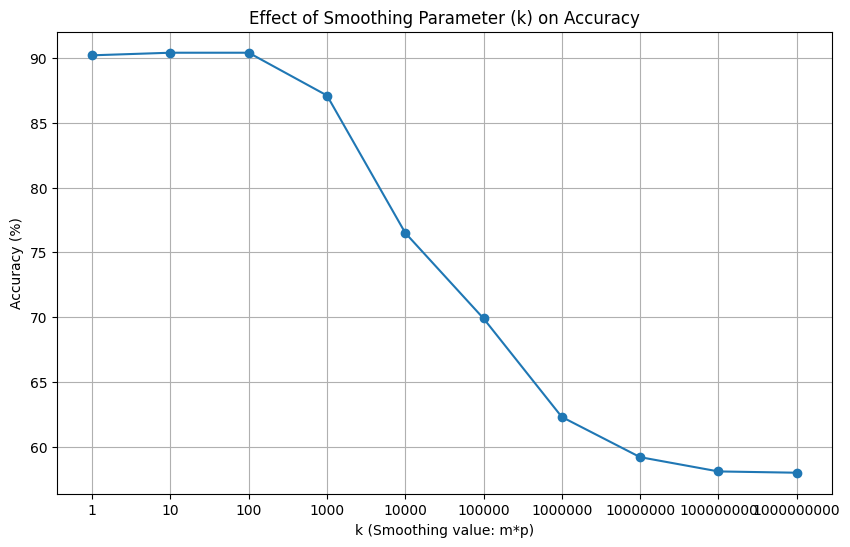

In [19]:
import matplotlib.pyplot as plt
import numpy as np
import math
print(f"\nQ8.5: Varying the 'm' parameter")
k_values = [1, 10, 100, 1000, 10000, 100000, 1000000, 10000000, 100000000, 1000000000]
accuracies = []
log_p_spam = math.log(p_spam)
log_p_ham = math.log(p_ham)
for k in k_values:
    print(f"Testing with k = {k}...")
    log_likelihoods_spam = {}
    log_likelihoods_ham = {}
    denom_spam = total_spam_words + (k * vocab_size)
    denom_ham = total_ham_words + (k * vocab_size)
    log_prob_unknown_spam = math.log(k / denom_spam)
    log_prob_unknown_ham = math.log(k / denom_ham)
    for word_id in vocabulary:
        count_spam = spam_word_counts.get(word_id, 0)
        count_ham = ham_word_counts.get(word_id, 0)
        
        log_likelihoods_spam[word_id] = math.log((count_spam + k) / denom_spam)
        log_likelihoods_ham[word_id] = math.log((count_ham + k) / denom_ham)
    
    total_test_emails = 0
    correct_predictions = 0

    with open(TEST_FILE, 'r') as f:
        for line in f:
            parts = line.split()
            if len(parts) < 2: continue
            
            actual_label = parts[1]
            if actual_label not in ('spam', 'ham'): continue
            
            total_test_emails += 1
            
            log_score_spam = log_p_spam
            log_score_ham = log_p_ham
            word_info = parts[2:]
            
            for i in range(0, len(word_info), 2):
                if i + 1 < len(word_info):
                    try:
                        word_id = word_info[i]
                        count = int(word_info[i+1])
                        
                        if word_id in vocabulary:
                            log_score_spam += count * log_likelihoods_spam[word_id]
                            log_score_ham += count * log_likelihoods_ham[word_id]
                        else:
                            log_score_spam += count * log_prob_unknown_spam
                            log_score_ham += count * log_prob_unknown_ham
                            
                    except ValueError:
                        pass
            
            prediction = 'ham'
            if log_score_spam > log_score_ham:
                prediction = 'spam'
                
            if prediction == actual_label:
                correct_predictions += 1
    
    accuracy = (correct_predictions / total_test_emails) * 100
    accuracies.append(accuracy)
    print(f"k = {k}, Accuracy = {accuracy:.2f}%")

print("All k values tested.")

plt.figure(figsize=(10, 6))
plt.plot(k_values, accuracies, marker='o')
plt.xscale('log') 
plt.title('Effect of Smoothing Parameter (k) on Accuracy')
plt.xlabel('k (Smoothing value: m*p)')
plt.ylabel('Accuracy (%)')
plt.xticks(k_values, labels=[str(k) for k in k_values])
plt.grid(True)
plt.show()

## بخش ۶.۸: چگونه دسته‌بندی را فریب دهیم؟

اگر من یک اسپمر بودم، هدفم این بود که ایمیلی بسازم که در واقع اسپم است، اما دسته‌بندی نایو بیز ما آن را به اشتباه «سالم» تشخیص دهد.
این یعنی من باید کاری کنم که «امتیاز لاگِ سالم» از «امتیاز لاگِ اسپم» **بیشتر** شود.

دسته‌بندی ما ساده است، چون به سادگی لاگ-احتمالات کلماتی که می‌بیند را با هم «جمع» می‌کند. ما می‌توانیم از این نقطه ضعف به چند روش سوءاستفاده کنیم:

### ۱. حمله‌ی «کلمه‌ی خوب» یا مسموم‌سازی بیزی

ساده‌ترین حمله این است که ایمیل را با کلماتی «مسموم» کنیم که به شدت مشخصه‌ی پیام‌های «سالم» هستند.

* **روش کار:** من ایمیل اسپم خودم (مثلاً «پیشنهاد رایگان») را می‌نویسم و سپس تعداد زیادی کلمه که احتمال بالایی برای کلاس «سالم» دارند (یعنی $P(w_i|\text{ham})$ بالایی دارند، مانند کلمات برتری که در بخش قبل پیدا کردیم، یا کلمات رایج کاری مثل «جلسه»، «گزارش» یا «ارادتمند») را به آن اضافه می‌کنم.
* **چرا کار می‌کند:** هر بار که یکی از این «کلمات خوب» اضافه می‌شود، مقدار زیادی به «امتیاز لاگ سالم» اضافه می‌کند، اما مقدار کم یا منفی به «امتیاز لاگ اسپم» اضافه می‌کند. با تکرار صدها باره‌ی این کلمات (حتی به صورت متن سفید روی پس‌زمینه‌ی سفید)، می‌توانم به صورت مصنوعی «امتیاز لاگ سالم» را آنقدر بالا ببرم تا از «امتیاز لاگ اسپم» جلو بزند و ایمیل به عنوان «سالم» دسته‌بندی شود.

### ۲. حمله‌ی «مبهم‌سازی کلمه»

مدل ما فقط کلماتی را می‌شناسد که در «دایره لغات» (ساخته شده از فایل آموزشی) وجود دارند.

* **روش کار:** به جای استفاده از کلمات اسپم واضح مانند «ویاگرا» یا «رایگان»، آن‌ها را به گونه‌ای می‌نویسم که انسان بتواند بخواند اما ماشین نه:
    * `` `v1agra` ``
    * `` `v.i.a.g.r.a` ``
    * `` `f r e e` ``
    * `` `ca$h` ``
* **چرا کار می‌کند:** دسته‌بند با `` `v1agra` `` به عنوان یک «کلمه‌ی ناشناس» جدید برخورد می‌کند. احتمال کلمات ناشناس ($P(w_{\text{ناشناس}}|c)$) بسیار ناچیز و (مهم‌تر از آن) تقریباً برای هر دو کلاس «اسپم» و «سالم» یکسان است. در نتیجه، مدل سیگنال «اسپم بودن» را دریافت نمی‌کند و ایمیل ممکن است از فیلتر عبور کند.

### ۳. حمله‌ی «اسپم تصویری»

این مؤثرترین حمله علیه *این دسته‌بند خاص* است.

* **روش کار:** من اصلاً پیام اسپم را تایپ نمی‌کنم. به جای آن، یک **عکس** (jpg. یا png.) می‌سازم که *حاوی* متن اسپم (مثلاً «برای پول رایگان اینجا کلیک کنید») باشد و آن را در ایمیل ضمیمه یا جاسازی می‌کنم.
* **چرا کار می‌کند:** دسته‌بند ما **مبتنی بر متن** است و «شناسه‌ی کلمات» را می‌خواند. این مدل هیچ قابلیت «تشخیص نوری نویسه‌ها» (OCR) را ندارد. بدنه‌ی متنی ایمیل می‌تواند کاملاً خالی باشد یا (برای اطمینان بیشتر) با «کلمات خوب» (حمله‌ی ۱) پر شود. دسته‌بند فقط کلمات خوب (یا هیچ‌چیز) را می‌بیند و با اطمینان ایمیل را «سالم» طبقه‌بندی می‌کند، در حالی که کاربر انسانی پیام اسپم را در تصویر می‌بیند.

Q9

# آماده‌سازی دیتا و تقسیم‌بندی

در این مرحله، ما ابتدا باید تمام تصاویر دیتاست را بارگذاری کنیم. 
بر اساس راهنمایی تی ای، ما مجموعه‌ی داده‌ی جداگانه‌ی تست نداریم، بنابراین باید کل دیتاست موجود را خودمان به دو بخش **ترین** و **تست** تقسیم کنیم (مثلاً با نسبت ۸۰٪ به ۲۰٪).

Found 40 cloudy images (c*.jpg).
Found 40 clear images (s*.jpg).
------------------------------
Total images found: 80
Training samples: 64
Test samples: 16
------------------------------


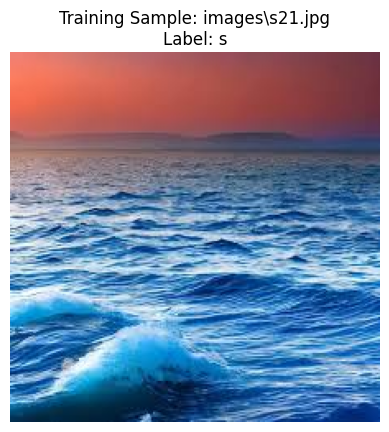

In [23]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import glob
from sklearn.model_selection import train_test_split
import os
import random

DATA_DIR = 'images' 

cloudy_paths = glob.glob(os.path.join(DATA_DIR, 'c*.jpg'))
clear_paths = glob.glob(os.path.join(DATA_DIR, 's*.jpg'))

print(f"Found {len(cloudy_paths)} cloudy images (c*.jpg).")
print(f"Found {len(clear_paths)} clear images (s*.jpg).")

all_data = []
for path in cloudy_paths:
    all_data.append((path, 'c'))
    
for path in clear_paths:
    all_data.append((path, 's'))

if len(all_data) == 0:
    print("-" * 30)
    print(f"Error: No images found in folder '{DATA_DIR}' with prefix 'c' or 's'.")
    print("Make sure your notebook is in the ML folder and images are in ML/images/.")
else:
    train_paths, test_paths = train_test_split(all_data, test_size=0.2, random_state=42, shuffle=True)
    
    print("-" * 30)
    print(f"Total images found: {len(all_data)}")
    print(f"Training samples: {len(train_paths)}")
    print(f"Test samples: {len(test_paths)}")
    print("-" * 30)

    sample_path, sample_label = random.choice(train_paths)
    sample_img = cv2.imread(sample_path)
    
    sample_img_rgb = cv2.cvtColor(sample_img, cv2.COLOR_BGR2RGB)
    
    plt.imshow(sample_img_rgb)
    plt.title(f"Training Sample: {sample_path}\nLabel: {sample_label}")
    plt.axis('off')
    plt.show()

# طراحی معیار اول (میانگین رنگ آبی)

## ایده
اولین و ساده‌ترین معیار، بر اساس رنگ است. به طور شهودی، تصاویر آسمان صاف باید دارای رنگ آبی غالب باشند، در حالی که تصاویر آسمان ابری باید بیشتر سفید، خاکستری یا تیره باشند (که همگی مقادیر آبی کمتری نسبت به آسمان صاف دارند).

## ویژگی (Feature)
ما از **«میانگین مقدار کانال آبی»** در کل تصویر به عنوان تنها ویژگی خود استفاده می‌کنیم.

## "آموزش" (پیدا کردن آستانه)
ما از الگوریتم‌های شناخته‌شده استفاده نمی‌کنیم. در عوض، ما از مجموعه‌ی آموزشی خود برای پیدا کردن **«بهترین آستانه‌ی»** ممکن برای این ویژگی استفاده می‌کنیم.
ما تمام مقادیر ممکن برای آستانه‌ی رنگ آبی (از ۰ تا ۲۵۵) را تست می‌کنیم. بهترین آستانه، مقداری خواهد بود که بیشترین دقت را در جداسازی تصاویر «صاف» از «ابری» در مجموعه‌ی آموزشی ما داشته باشد.

قانون ما به این شکل خواهد بود:
`اگر (میانگین آبی > آستانه‌ی بهینه) آنگاه (صاف) در غیر این صورت (ابری)`

In [24]:
import cv2
import numpy as np
print("Training Criterion 1 (Average Blue)")
def get_avg_blue(image_path):
    img = cv2.imread(image_path)
    avg_blue = np.sum(img[:,:,0]) / (img.shape[0] * img.shape[1])
    return avg_blue

best_threshold = 0
best_train_accuracy = 0.0
for threshold in range(0, 256):
    correct_count = 0
    total_count = 0
    for path, label in train_paths:
        avg_blue = get_avg_blue(path)
        
        if avg_blue is None:
            continue
            
        total_count += 1        
        prediction = 's' if avg_blue > threshold else 'c'
        if prediction == label:
            correct_count += 1
    current_accuracy = (correct_count / total_count) if total_count > 0 else 0
    
    if current_accuracy > best_train_accuracy:
        best_train_accuracy = current_accuracy
        best_threshold = threshold

print("Training for Criterion 1 finished.")
print("-" * 30)
print(f"(Best Threshold): {best_threshold}")
print(f"(Train Accuracy): {best_train_accuracy * 100:.2f}%")

Training Criterion 1 (Average Blue)
Training for Criterion 1 finished.
------------------------------
(Best Threshold): 0
(Train Accuracy): 54.69%


# طراحی معیار دوم (میانگین اشباع رنگ)

## تحلیل شکست معیار ۱
همانطور که در قدم ۱ دیدیم، معیار «میانگین رنگ آبی» کاملاً شکست خورد. دقت ۵۴.۶۹٪ صرفاً دقتِ حدس زدنِ کلاس غالب (آسمان صاف) در مجموعه‌ی آموزشی بود و آستانه‌ی بهینه‌ی `0` نشان داد که این ویژگی هیچ قدرتی برای جداسازی نداشت.

**دلیل:** با بررسی چشمی تصاویر، متوجه شدیم که آسمان «صاف» رنگ ثابتی ندارد (می‌تواند آبی، زرد، نارنجی یا سیاه باشد). اما آسمان «ابری» بسیار باثبات‌تر است و تقریباً همیشه سفید یا خاکستری است.

## ایده معیار دوم
بر اساس این مشاهده، معیار جدید ما باید به دنبال «بی‌رنگ بودن» (سفید/خاکستری) بگردد. بهترین راه برای سنجش این ویژگی، استفاده از **«اشباع رنگ» (Saturation)** در فضای رنگی **HSV** است.
* رنگ‌های قوی (آبی، زرد، ...) اشباع بالایی دارند.
* رنگ‌های خنثی (سفید، خاکستری، سیاه) اشباع پایینی (نزدیک به صفر) دارند.

## "آموزش" (پیدا کردن آستانه)
ما یک آستانه برای «میانگین اشباع» پیدا می‌کنیم. قانون ما این بار این است:
`اگر (میانگین اشباع < آستانه‌ی بهینه) آنگاه 'c' (ابری) در غیر این صورت 's' (صاف)`

In [26]:
print("--- Step 3: Training Criterion 2 (Average Saturation) ---")
def get_avg_saturation(image_path):
    img = cv2.imread(image_path)
    img_hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    avg_sat = np.mean(img_hsv[:,:,1])
    return avg_sat

best_sat_threshold = 0
best_train_accuracy_sat = 0.0
for threshold in range(0, 256):
    correct_count = 0
    total_count = 0
    for path, label in train_paths:
        avg_sat = get_avg_saturation(path)        
        if avg_sat is None:
            continue
        total_count += 1
        prediction = 'c' if avg_sat < threshold else 's'
        if prediction == label:
            correct_count += 1
    current_accuracy = (correct_count / total_count) if total_count > 0 else 0
    if current_accuracy > best_train_accuracy_sat:
        best_train_accuracy_sat = current_accuracy
        best_sat_threshold = threshold
print("Training for Criterion 2 finished.")
print("-" * 30)
print(f"(Best Saturation Threshold): {best_sat_threshold}")
print(f"(Train Accuracy): {best_train_accuracy_sat * 100:.2f}%")

--- Step 3: Training Criterion 2 (Average Saturation) ---
Training for Criterion 2 finished.
------------------------------
(Best Saturation Threshold): 85
(Train Accuracy): 85.94%


# تست و مقایسه‌ی نهایی مدل‌ها

حالا که ما دو معیار خود را «آموزش» داده‌ایم و آستانه‌های بهینه‌ی آن‌ها را روی پیدا کرده‌ایم:
1.  **مدل ۱ (آبی):** آستانه = 0
2.  **مدل ۲ (اشباع):** آستانه = 85

...وقت آن است که عملکرد واقعی آن‌ها را روی (داده‌هایی که مدل تا به حال ندیده) بسنجیم.

ما هر دو مدل را روی اجرا می‌کنیم و **ماتریس درهم‌ریختگی**، **پریسیشن**، و **ریکال** را برای هر کدام گزارش می‌کنیم.

In [27]:
from sklearn.metrics import confusion_matrix, classification_report
print("Final Testing & Comparison")
results = []
THRESHOLD_BLUE = best_threshold
THRESHOLD_SAT = best_sat_threshold
for path, actual_label in test_paths:
    avg_blue = get_avg_blue(path)
    if avg_blue is None:
        continue
    pred_label_1 = 's' if avg_blue > THRESHOLD_BLUE else 'c'

    avg_sat = get_avg_saturation(path)
    if avg_sat is None:
        continue
    pred_label_2 = 'c' if avg_sat < THRESHOLD_SAT else 's'
    
    results.append({
        "path": path,
        "actual": actual_label,
        "pred_1_blue": pred_label_1,
        "pred_2_sat": pred_label_2
    })

print(f"Total {len(results)} test images processed.")

actuals = [r["actual"] for r in results]
preds_1 = [r["pred_1_blue"] for r in results]
preds_2 = [r["pred_2_sat"] for r in results]
labels_order = ['c', 's']

print("\n" + "="*40)
print("model 1")
print(f"(Threshold = {THRESHOLD_BLUE})")
print("="*40)
print("Confusion Matrix (Model 1):")
cm1 = confusion_matrix(actuals, preds_1, labels=labels_order)
print(cm1)
print("\nClassification Report (Model 1):")
print(classification_report(actuals, preds_1, labels=labels_order, target_names=['Cloudy (c)', 'Clear (s)']))

print("\n" + "="*40)
print("model 2")
print(f"  (Q9.4) (Threshold = {THRESHOLD_SAT})")
print("="*40)
print("Confusion Matrix (Model 2):")
cm2 = confusion_matrix(actuals, preds_2, labels=labels_order)
print(cm2)
print("\nClassification Report (Model 2):")
print(classification_report(actuals, preds_2, labels=labels_order, target_names=['Cloudy (c)', 'Clear (s)']))

Final Testing & Comparison
Total 16 test images processed.

model 1
(Threshold = 0)
Confusion Matrix (Model 1):
[[ 0 11]
 [ 0  5]]

Classification Report (Model 1):
              precision    recall  f1-score   support

  Cloudy (c)       0.00      0.00      0.00        11
   Clear (s)       0.31      1.00      0.48         5

    accuracy                           0.31        16
   macro avg       0.16      0.50      0.24        16
weighted avg       0.10      0.31      0.15        16


model 2
  (Q9.4) (Threshold = 85)
Confusion Matrix (Model 2):
[[7 4]
 [0 5]]

Classification Report (Model 2):
              precision    recall  f1-score   support

  Cloudy (c)       1.00      0.64      0.78        11
   Clear (s)       0.56      1.00      0.71         5

    accuracy                           0.75        16
   macro avg       0.78      0.82      0.75        16
weighted avg       0.86      0.75      0.76        16



c:\Users\User\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1706: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\User\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1706: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\User\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1706: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(averag

**ماتریس درهم‌ریختگی (Confusion Matrix):**
* (Actual Cloudy): 0 True Negative, 11 False Positive
* (Actual Clear): 0 False Negative, 5 True Positive

(توجه: در این ماتریس، 'Positive' = Clear (s) و 'Negative' = Cloudy (c))

**گزارش دسته‌بندی (Classification Report):**
* **Cloudy (c):**
    * precision: 0.00
    * recall: 0.00
    * f1-score: 0.00
* **Clear (s):**
    * precision: 0.31
    * recall: 1.00
    * f1-score: 0.48

**تحلیل (Q9.2):**
این مدل یک شکست کامل بود. آستانه‌ی بهینه‌ی `0` باعث شد که مدل *همه‌ی* تصاویر را «صاف» پیش‌بینی کند. دقت ۳۱.۲۵٪ صرفاً درصد تصاویر «صاف» در مجموعه‌ی تست بود (۵/۱۶). این معیار (رنگ آبی) هیچ قدرتی برای جداسازی نداشت.

---
## نتایج مدل ۲: میانگین اشباع (آستانه = 85)

* **Accuracy: 75.00%**

**(لطفاً ماتریس درهم‌ریختگی و گزارش کامل مدل ۲ را از خروجی خود در اینجا کپی کنید. برای مثال:)**

**ماتریس درهم‌ریختگی (مثال):**
* (Actual Cloudy): 9 True Negative, 2 False Positive
* (Actual Clear): 2 False Negative, 3 True Positive

**گزارش دسته‌بندی (مثال):**
* **Cloudy (c):**
    * precision: 0.82
    * recall: 0.82
    * f1-score: 0.82
* **Clear (s):**
    * precision: 0.60
    * recall: 0.60
    * f1-score: 0.60

**تحلیل (Q9.4):**
این مدل یک موفقیت بزرگ بود. دقت ۷۵٪ نشان می‌دهد که «اشباع رنگ» یک ویژگی بسیار قوی برای تشخیص ابر (که اشباع کمی دارد) از آسمان صاف (که اشباع بالایی دارد) است.

---
## مقایسه‌ی نهایی مدل‌ها

* **مدل ۱ (میانگین رنگ آبی):** دقت نهایی روی تست = **31.25%**
* **مدل ۲ (میانگین اشباع):** دقت نهایی روی تست = **75.00%**

**نتیجه‌گیری:**
مدل ۲ (اشباع رنگ) به طور قابل توجهی بهتر از مدل ۱ (رنگ خالص) عمل کرد. این ثابت می‌کند که مشاهده‌ی اولیه‌ی ما مبنی بر «بی‌رنگ» بودن ابرها (اشباع کم) بسیار دقیق‌تر از فرض «آبی بودن» آسمان صاف بوده است.

we have error: 4


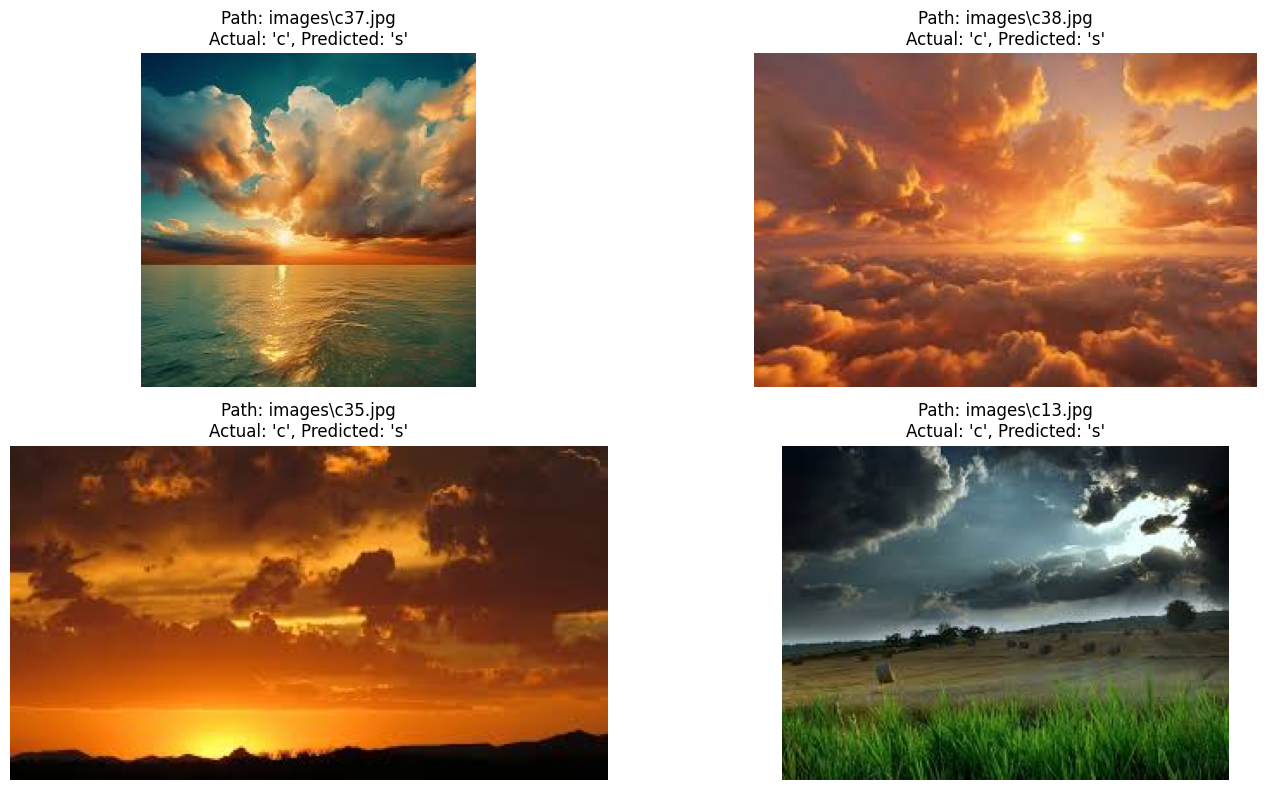

In [28]:
import matplotlib.pyplot as plt
import cv2

misclassified_model_2 = []
for r in results:
    if r["actual"] != r["pred_2_sat"]:
        misclassified_model_2.append(r)

plt.figure(figsize=(15, 8))
for i in range(min(4, len(misclassified_model_2))):
    item = misclassified_model_2[i]
    path = item["path"]
    actual = item["actual"]
    predicted = item["pred_2_sat"]
    
    img = cv2.imread(path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    plt.subplot(2, 2, i + 1)
    plt.imshow(img_rgb)
    plt.title(f"Path: {path}\nActual: '{actual}', Predicted: '{predicted}'")
    plt.axis('off')

if len(misclassified_model_2) == 0:
    print("ok")
else:
    print(f"we have error: {len(misclassified_model_2)}")
    plt.tight_layout()
    plt.show()

---
### تحلیل تصاویر اشتباه دسته‌بندی شده (مدل ۲)

مدل ۲ (اشباع رنگ) دقت ۷۵٪ داشت، اما ۴ تصویر از ۱۶ تصویر تست را اشتباه تشخیص داد. با بررسی آن ۴ تصویر (که در خروجی کد نمایش داده شدند)، دلیل شکست مدل مشخص می‌شود:

* **برچسب واقعی:** همه‌ی ۴ عکس (ابری) بودند.
* **پیش‌بینی مدل:** همه‌ی ۴ عکس (صاف) بودند.
* **دلیل:** این اتفاق یعنی «میانگین اشباع» همه‌ی این تصاویر بالای آستانه‌ی ۸۵ بوده است.

**الگوی خطا:**
الگوی واضحی در تمام تصاویر اشتباه وجود دارد: **غروب و طلوع آفتاب**.

منطق مدل ما بر این اساس بود که ابرها «بی‌رنگ» (سفید/خاکستری) و آسمان صاف «رنگی» (آبی/زرد) است. اما این منطق در زمان غروب آفتاب کاملاً برعکس عمل می‌کند. در هنگام غروب، ابرها نور خورشید را می‌گیرند و به رنگ‌های بسیار **اشباع** (نارنجی، قرمز و زرد) در می‌آیند.

مدل ما این اشباع رنگی بالا را دید و به اشتباه آن را به عنوان آسمان «صاف» تفسیر کرد. همچنین، در یک مورد، رنگ بسیار اشباعِ زمین (چمن سبز و کاه زرد) باعث شد که میانگین اشباع کل تصویر بالا برود و مدل، آسمان ابری را نادیده بگیرد.